In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("anggadwisunarto/potholes-detection-yolov8")

print("Path to dataset files:", path)

100%|██████████| 718M/718M [00:05<00:00, 126MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/anggadwisunarto/potholes-detection-yolov8/versions/3


In [3]:
# randomly partition a test set, since the one from kaggle only contained validation and training sets

import os
import shutil
import random

writable_path = "/content/dataset"

if not os.path.exists(writable_path):
    print(f"Copying dataset from read-only cache to {writable_path}...")
    shutil.copytree(path, writable_path)
    print("Copy complete.")

def create_test_split(dataset_path, split_ratio=0.5):
    val_images_dir = os.path.join(dataset_path, 'valid', 'images')
    val_labels_dir = os.path.join(dataset_path, 'valid', 'labels')

    test_images_dir = os.path.join(dataset_path, 'test', 'images')
    test_labels_dir = os.path.join(dataset_path, 'test', 'labels')

    os.makedirs(test_images_dir, exist_ok=True)
    os.makedirs(test_labels_dir, exist_ok=True)

    if not os.path.exists(val_images_dir):
        print(f"Validation directory not found at {val_images_dir}.")
        return

    # list all validation images
    images = [f for f in os.listdir(val_images_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
    num_to_move = int(len(images) * split_ratio)

    # randomly select images to move
    sampled_images = random.sample(images, num_to_move)

    moved_count = 0
    for img_name in sampled_images:
        # paths for image
        src_img = os.path.join(val_images_dir, img_name)
        dst_img = os.path.join(test_images_dir, img_name)

        # corresponding label file name
        base_name = os.path.splitext(img_name)[0]
        label_name = f"{base_name}.txt"

        src_label = os.path.join(val_labels_dir, label_name)
        dst_label = os.path.join(test_labels_dir, label_name)

        # move image and label
        if os.path.exists(src_img):
            shutil.move(src_img, dst_img)

            if os.path.exists(src_label):
                shutil.move(src_label, dst_label)
            moved_count += 1

    print(f"Successfully moved {moved_count} items to the test set.")

create_test_split(writable_path, split_ratio=0.5)
path = writable_path

Copying dataset from read-only cache to /content/dataset...
Copy complete.
Successfully moved 198 items to the test set.


In [4]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 45.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 10.9 MB/s eta 0:00:00


In [6]:
import yaml

# update paths in data.yaml to refer to /content/dataset
yaml_path = '/content/dataset/data.yaml'

with open(yaml_path, 'r') as f:
    data = yaml.safe_load(f)

data['path'] = '/content/dataset'
data['train'] = 'train/images'
data['val'] = 'valid/images'
data['test'] = 'test/images'

with open(yaml_path, 'w') as f:
    yaml.dump(data, f, default_flow_style=False)

In [8]:
from ultralytics import YOLO

# load the pre-trained model
model = YOLO('yolo26m.pt')

results = model.train(
    data='/content/dataset/data.yaml',
    epochs=100,
    imgsz=640,
    batch=16,
    device=0,
    project='pothole_detection',
    name='yolo26m'
)

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo26m, nbs=64, nms=None, opset=None, optimize=False, optimi

In [10]:
from ultralytics import YOLO
import os

# load the model
best_model_path = '/content/runs/detect/pothole_detection/yolo26m/weights/best.pt'
model = YOLO(best_model_path)

# evaluate performance
eval_results = model.val(data='/content/dataset/data.yaml', split='test')

print("Evaluation Metrics")
print(f"mAP50: {eval_results.results_dict['metrics/mAP50(B)']:.4f}")
print(f"mAP50-95: {eval_results.results_dict['metrics/mAP50-95(B)']:.4f}")
print(f"Precision (P): {eval_results.results_dict['metrics/precision(B)']:.4f}")
print(f"Recall (R): {eval_results.results_dict['metrics/recall(B)']:.4f}")

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26m summary (fused): 130 layers, 20,350,223 parameters, 0 gradients, 68.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 72.1±28.2 MB/s, size: 469.5 KB)
val: Scanning /content/dataset/test/labels... 198 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 198/198 190.5it/s 1.0s
val: /content/dataset/test/images/pothole_975.jpg: corrupt JPEG restored and saved
val: New cache created: /content/dataset/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 1.9it/s 6.7s
                   all        198        576      0.797      0.797       0.83      0.575
Speed: 1.4ms preprocess, 22.1ms inference, 0.0ms loss, 2.1ms postprocess per image
Results saved to /content/runs/detect/val
Evaluation Metrics
mAP50: 0.8303
mAP50-95: 0.5748
Precision (P): 0.7969
Recall (R): 0.7969



0: 640x640 1 pothole, 39.6ms
1: 640x640 2 potholes, 39.6ms
2: 640x640 9 potholes, 39.6ms
Speed: 1.7ms preprocess, 39.6ms inference, 3.1ms postprocess per image at shape (1, 3, 640, 640)


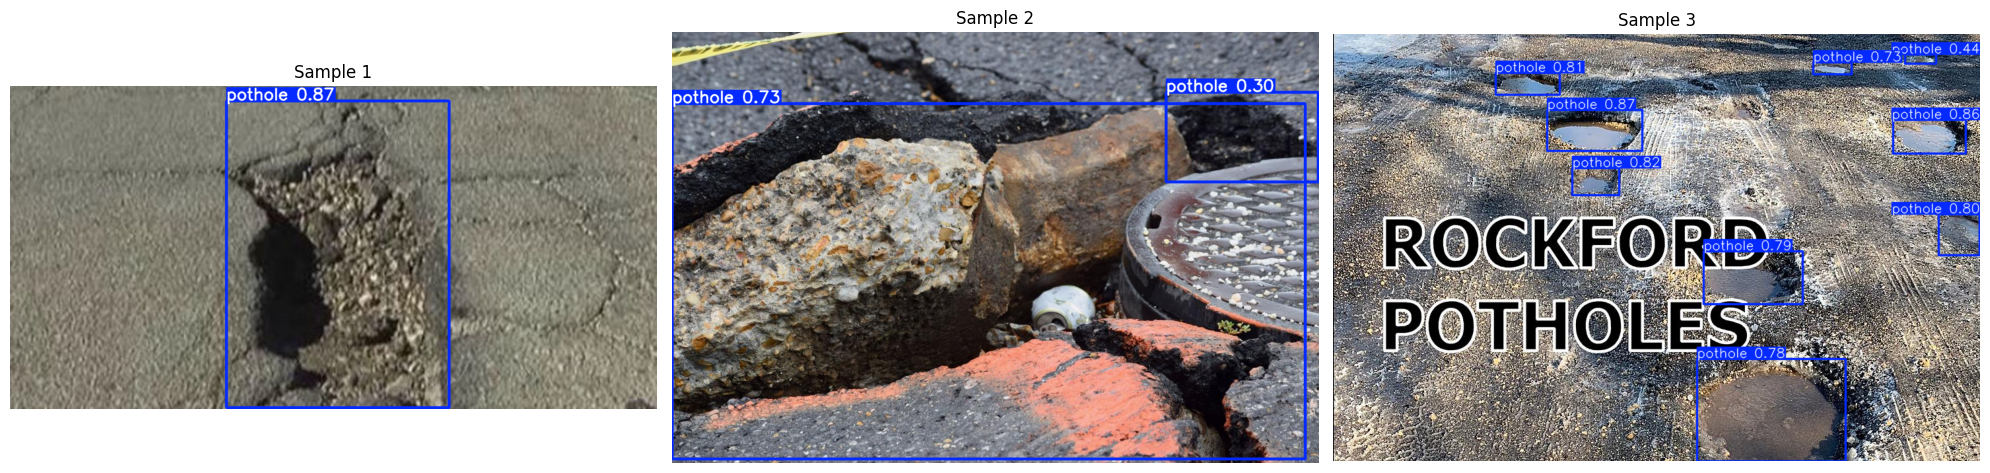

In [11]:
import glob
import matplotlib.pyplot as plt
import cv2

test_images = glob.glob('/content/dataset/test/images/*.jpg') + glob.glob('/content/dataset/test/images/*.png') + glob.glob('/content/dataset/test/images/*.jpeg')
sample_test_images = test_images[:3]

results = model.predict(source=sample_test_images, conf=0.25, save=False)

# visualize the predictions
fig, axes = plt.subplots(1, 3, figsize=(20, 10))
for i, result in enumerate(results):
    annotated_img = cv2.cvtColor(result.plot(), cv2.COLOR_BGR2RGB)
    axes[i].imshow(annotated_img)
    axes[i].axis('off')
    axes[i].set_title(f"Sample {i+1}")

plt.tight_layout()
plt.show()